<a href="https://colab.research.google.com/github/Malik-Zain-555/resume-category-classifier/blob/main/resume-category-classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import pandas as pd
file_path = "/content/drive/MyDrive/Datasets - ML/Resume.csv"
df = pd.read_csv(file_path)

In [3]:
df.head()

,ID,Resume_str,Resume_html,Category
0,16852973,HR ADMINISTRATOR/MARKETING ASSOCIATE\...,"<div class=""fontsize fontface vmargins hmargin...",HR
1,22323967,"HR SPECIALIST, US HR OPERATIONS ...","<div class=""fontsize fontface vmargins hmargin...",HR
2,33176873,HR DIRECTOR Summary Over 2...,"<div class=""fontsize fontface vmargins hmargin...",HR
3,27018550,HR SPECIALIST Summary Dedica...,"<div class=""fontsize fontface vmargins hmargin...",HR
4,17812897,HR MANAGER Skill Highlights ...,"<div class=""fontsize fontface vmargins hmargin...",HR


In [4]:
df.shape

(2484, 4)

In [5]:
df.isnull().sum()

,0
ID,0
Resume_str,0
Resume_html,0
Category,0


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2484 entries, 0 to 2483
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   ID           2484 non-null   int64 
 1   Resume_str   2484 non-null   object
 2   Resume_html  2484 non-null   object
 3   Category     2484 non-null   object
dtypes: int64(1), object(3)
memory usage: 77.8+ KB


In [7]:
df['Category'].value_counts()

,count
Category,
INFORMATION-TECHNOLOGY,120
BUSINESS-DEVELOPMENT,120
ADVOCATE,118
CHEF,118
ENGINEERING,118
ACCOUNTANT,118
FINANCE,118
FITNESS,117
AVIATION,117


In [8]:
df['Category'].nunique()

24

<Axes: xlabel='count', ylabel='Category'>

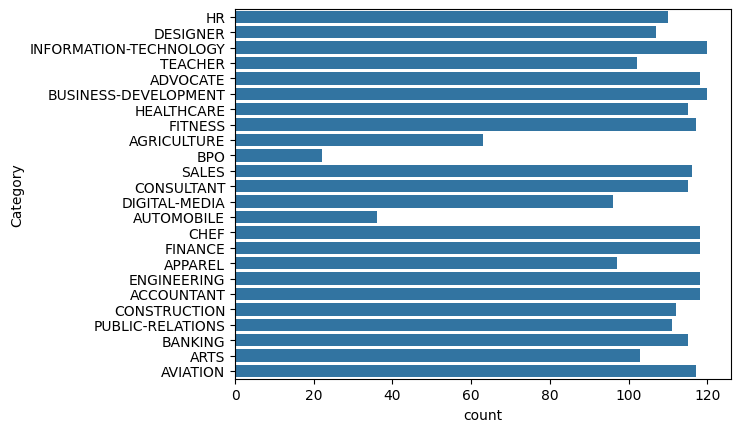

In [9]:
import seaborn as sn

sn.countplot(df['Category'])

In [10]:
df['Resume_str'] = df['Resume_str'].str.lower()
df.head()

,ID,Resume_str,Resume_html,Category
0,16852973,hr administrator/marketing associate\...,"<div class=""fontsize fontface vmargins hmargin...",HR
1,22323967,"hr specialist, us hr operations ...","<div class=""fontsize fontface vmargins hmargin...",HR
2,33176873,hr director summary over 2...,"<div class=""fontsize fontface vmargins hmargin...",HR
3,27018550,hr specialist summary dedica...,"<div class=""fontsize fontface vmargins hmargin...",HR
4,17812897,hr manager skill highlights ...,"<div class=""fontsize fontface vmargins hmargin...",HR


In [11]:
df['Resume_str'].str.count(r'[^\w\s]')

,Resume_str
0,152
1,130
2,197
3,50
4,279
...,...
2479,143
2480,172
2481,55
2482,174


In [12]:
import re

def clean_resume(text):
    # 1. Lowercase
    text = text.lower()

    # 2. Remove URLs
    text = re.sub(r'http\S+|www\.\S+', ' ', text)

    # 3. Remove email addresses
    text = re.sub(r'\S+@\S+', ' ', text)

    # 4. Remove special characters, numbers, and punctuation
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)

    # 5. Collapse extra spaces and strip trailing/leading spaces
    text = re.sub(r'\s+', ' ', text).strip()

    return text

In [13]:
df['Resume_str'] = df['Resume_str'].apply(clean_resume)
df.head()

,ID,Resume_str,Resume_html,Category
0,16852973,hr administrator marketing associate hr admini...,"<div class=""fontsize fontface vmargins hmargin...",HR
1,22323967,hr specialist us hr operations summary versati...,"<div class=""fontsize fontface vmargins hmargin...",HR
2,33176873,hr director summary over years experience in r...,"<div class=""fontsize fontface vmargins hmargin...",HR
3,27018550,hr specialist summary dedicated driven and dyn...,"<div class=""fontsize fontface vmargins hmargin...",HR
4,17812897,hr manager skill highlights hr skills hr depar...,"<div class=""fontsize fontface vmargins hmargin...",HR


### Train/Test Split & Feature Representation (TF-IDF Vectorization)

In [14]:
x = df['Resume_str']
y = df['Category']

from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)


In [15]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    stop_words='english',
    max_features=3000,
    ngram_range=(1,2)
)

x_train_tfidf = tfidf.fit_transform(x_train)
x_test_tfidf = tfidf.transform(x_test)

In [16]:
print(x_train_tfidf.shape)
print(x_test_tfidf.shape)

(1987, 3000)
(497, 3000)


In [17]:
# Look at 20 sample features (words/phrases) chosen by TF-IDF
print(tfidf.get_feature_names_out()[:20])

['abilities' 'ability' 'ability work' 'able' 'absence' 'abuse' 'academic'
 'academy' 'acceptance' 'accepted' 'access' 'access excel' 'accessories'
 'accommodate' 'accomplish' 'accomplished' 'accomplishments' 'accordance'
 'according' 'account']


In [18]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score

# 1. Initialize and train the classifier
# max_iter=1000 ensures gradient descent converges across 24 classes
logReg = LogisticRegression(max_iter=1000, random_state=42)
logReg.fit(x_train_tfidf, y_train)

# 2. Predict on unseen test data
y_pred = logReg.predict(x_test_tfidf)

# 3. Evaluate overall and per-class performance
print(f"Overall Accuracy: {accuracy_score(y_test, y_pred):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred))

Overall Accuracy: 0.6620

Classification Report:
                        precision    recall  f1-score   support

            ACCOUNTANT       0.67      0.83      0.74        24
              ADVOCATE       0.36      0.54      0.43        24
           AGRICULTURE       1.00      0.46      0.63        13
               APPAREL       0.67      0.21      0.32        19
                  ARTS       0.46      0.29      0.35        21
            AUTOMOBILE       0.00      0.00      0.00         7
              AVIATION       0.85      0.71      0.77        24
               BANKING       0.75      0.65      0.70        23
                   BPO       0.00      0.00      0.00         4
  BUSINESS-DEVELOPMENT       0.56      0.92      0.70        24
                  CHEF       0.86      0.75      0.80        24
          CONSTRUCTION       0.85      0.77      0.81        22
            CONSULTANT       0.56      0.22      0.31        23
              DESIGNER       0.89      0.81      0.85 

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [19]:
print(logReg.coef_.shape)

(24, 3000)


In [20]:
df["Category"].value_counts()

,count
Category,
INFORMATION-TECHNOLOGY,120
BUSINESS-DEVELOPMENT,120
ADVOCATE,118
CHEF,118
ENGINEERING,118
ACCOUNTANT,118
FINANCE,118
FITNESS,117
AVIATION,117


In [21]:
print(logReg.classes_)
print(logReg.coef_[19])

['ACCOUNTANT' 'ADVOCATE' 'AGRICULTURE' 'APPAREL' 'ARTS' 'AUTOMOBILE'
 'AVIATION' 'BANKING' 'BPO' 'BUSINESS-DEVELOPMENT' 'CHEF' 'CONSTRUCTION'
 'CONSULTANT' 'DESIGNER' 'DIGITAL-MEDIA' 'ENGINEERING' 'FINANCE' 'FITNESS'
 'HEALTHCARE' 'HR' 'INFORMATION-TECHNOLOGY' 'PUBLIC-RELATIONS' 'SALES'
 'TEACHER']
[-0.0523075  -0.06531948 -0.02038747 ...  0.06665042 -0.11463253
  0.07851808]


In [22]:
tfidf.get_feature_names_out()[0]

'abilities'

In [23]:
import numpy as np

np.argmax(logReg.coef_[19])

np.int64(1271)

In [24]:
tfidf.get_feature_names_out()[1271]

'hr'

In [25]:
new = np.argsort(logReg.coef_[19])[-10:]
new

array([ 516,  898, 2316,  900, 2240, 1941, 1276, 1274,  897, 1271])

In [26]:
tfidf.get_feature_names_out()[new]

array(['compensation', 'employee relations', 'resources', 'employees',
       'recruitment', 'payroll', 'human resources', 'human', 'employee',
       'hr'], dtype=object)

Every Category - 10 Word

In [27]:
list(logReg.classes_).index("BPO")

8

In [28]:
for class_name, coef in zip(logReg.classes_, logReg.coef_):
    listInNumbers = np.argsort(coef)[-10:]
    print(class_name)
    print(tfidf.get_feature_names_out()[listInNumbers])
    print(50*"-")



ACCOUNTANT
['financial statements' 'ledger' 'bank' 'entries' 'payroll' 'tax'
 'accounts' 'financial' 'accounting' 'accountant']
--------------------------------------------------
ADVOCATE
['case' 'violence' 'patient' 'children' 'court' 'health' 'care' 'child'
 'customer' 'advocate']
--------------------------------------------------
AGRICULTURE
['chemistry' 'public' 'laboratory' 'student' 'program' 'land' 'water'
 'students' 'research' 'agriculture']
--------------------------------------------------
APPAREL
['buyer' 'inventory' 'sales' 'product' 'fashion' 'production'
 'merchandise' 'merchandising' 'store' 'apparel']
--------------------------------------------------
ARTS
['english' 'students' 'dance' 'student' 'language arts' 'music' 'dental'
 'school' 'art' 'arts']
--------------------------------------------------
AUTOMOBILE
['vehicle' 'liability' 'insurance' 'mechanical' 'fraud' 'customer service'
 'customer' 'tibco' 'service' 'claims']
--------------------------------------------

In [29]:
df[df["Resume_str"].str.contains("dental")].groupby("Category").size()


,0
Category,
ACCOUNTANT,6
ADVOCATE,7
ARTS,4
AVIATION,2
BANKING,4
BUSINESS-DEVELOPMENT,1
CHEF,1
CONSULTANT,4
DESIGNER,2


In [30]:
arts = list(logReg.classes_).index("ARTS")
healthcare = list(logReg.classes_).index("HEALTHCARE")

In [31]:
dental = list(tfidf.get_feature_names_out()).index("dental")
print(logReg.coef_[arts].max(), logReg.coef_[healthcare].max())
print(logReg.coef_[arts][dental])
print(logReg.coef_[healthcare][dental])

3.479218359661794 5.345793489582118
1.292309742154549
0.3091702875137415


In [32]:
print("Train:", logReg.score(x_train_tfidf, y_train))
print("Test:", logReg.score(x_test_tfidf, y_test))

Train: 0.8102667337695018
Test: 0.6619718309859155


In [33]:
for C in [0.1, 1, 10, 100, 1000]:
    m = LogisticRegression(C=C, max_iter=1000, random_state=42)
    m.fit(x_train_tfidf, y_train)
    print(f"C={C} | train={m.score(x_train_tfidf, y_train):.4f} | test={m.score(x_test_tfidf, y_test):.4f}")

C=0.1 | train=0.6301 | test=0.6036
C=1 | train=0.8103 | test=0.6620
C=10 | train=0.9955 | test=0.7062
C=100 | train=1.0000 | test=0.7183
C=1000 | train=1.0000 | test=0.7123


In [34]:
for w in ['frontend', 'front end', 'mongodb', 'mongo']:
    print(w, df['Resume_str'].str.contains(w).sum())

frontend 8
front end 44
mongodb 4
mongo 5


In [35]:
new_resume = ["I'm Zain student of Riphah International University. I have 3+ year experience of web dev as a Frontend and I did backend and database. Used Mongo DB and mySQL and other stuff."]
cleaned_resume = clean_resume(new_resume[0])

final_model = LogisticRegression(C=100, max_iter=1000, random_state=42)
final_model.fit(x_train_tfidf, y_train)

x_new = tfidf.transform([cleaned_resume])
print(final_model.predict(x_new))

probs = final_model.predict_proba(x_new)[0]
top3 = np.argsort(probs)[-3:]
print(final_model.classes_[top3], probs[top3])

['CONSULTANT']
['BUSINESS-DEVELOPMENT' 'TEACHER' 'CONSULTANT'] [0.12811193 0.12942061 0.15690378]


In [36]:
for w in ['frontend', 'mysql', 'mongo', 'web', 'database', 'student']:
    print(w, w in tfidf.vocabulary_)

seen = [w for w in cleaned_resume.split() if w in tfidf.vocabulary_]
print(seen, len(seen), "out of", len(cleaned_resume.split()))

frontend False
mysql True
mongo False
web True
database True
student True
['student', 'international', 'university', 'year', 'experience', 'web', 'did', 'database', 'used', 'mysql'] 10 out of 32


In [37]:
tfidf_char = TfidfVectorizer(
    analyzer="char_wb",
    ngram_range=(3,5),
    max_features=10000
)
x_train_tfidf_char = tfidf_char.fit_transform(x_train)
x_test_tfidf_char = tfidf_char.transform(x_test)

In [38]:
print(x_train_tfidf_char.shape)
print(x_test_tfidf_char.shape)

(1987, 10000)
(497, 10000)


In [39]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score

logReg_char = LogisticRegression(max_iter=1000, random_state=42,C=100)
logReg_char.fit(x_train_tfidf_char, y_train)

y_pred_char = logReg_char.predict(x_test_tfidf_char)

print(f"Overall Accuracy: {accuracy_score(y_test, y_pred_char):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred_char))

Overall Accuracy: 0.6821

Classification Report:
                        precision    recall  f1-score   support

            ACCOUNTANT       0.74      0.83      0.78        24
              ADVOCATE       0.55      0.67      0.60        24
           AGRICULTURE       0.54      0.54      0.54        13
               APPAREL       0.44      0.37      0.40        19
                  ARTS       0.50      0.38      0.43        21
            AUTOMOBILE       1.00      0.43      0.60         7
              AVIATION       0.80      0.67      0.73        24
               BANKING       0.84      0.70      0.76        23
                   BPO       0.33      0.25      0.29         4
  BUSINESS-DEVELOPMENT       0.56      0.83      0.67        24
                  CHEF       0.80      0.67      0.73        24
          CONSTRUCTION       0.76      0.73      0.74        22
            CONSULTANT       0.67      0.52      0.59        23
              DESIGNER       0.94      0.76      0.84 

In [40]:
logReg_char.coef_

array([[ 0.26556636,  0.20419534,  0.51676206, ..., -0.05321706,
        -0.01160594, -0.01140617],
       [-1.33812107, -1.32666459, -1.39511689, ...,  0.20436537,
         0.12254049,  0.12639259],
       [ 0.81307346, -0.00651904, -0.00920566, ..., -0.24197056,
        -0.17339453, -0.17288985],
       ...,
       [-1.17772113, -0.05152784,  0.47167149, ...,  1.0349174 ,
         0.08939717,  0.08999246],
       [ 0.26721492,  0.31968432,  0.45604586, ...,  0.48277371,
         0.23006259,  0.25452073],
       [ 1.43876505,  0.13732191,  0.06268265, ...,  0.07096156,
         0.10805664,  0.11051384]])

In [41]:
print('ron' in tfidf_char.vocabulary_)
print('front' in tfidf_char.vocabulary_)

True
True


In [42]:
x = tfidf_char.transform([cleaned_resume])
print(logReg_char.predict(x))

['INFORMATION-TECHNOLOGY']


In [48]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score

word_pipe = Pipeline([
  ('tfidf', TfidfVectorizer(stop_words='english', max_features=3000, ngram_range=(1,2))),
  ('clf', LogisticRegression(C=100, max_iter=1000, random_state=42))
])

char_pipe = Pipeline([
    ('tfidf', TfidfVectorizer(analyzer='char_wb', max_features=10000, ngram_range=(3,5))),
    ('clf', LogisticRegression(C=100, max_iter=1000, random_state=42))
])

for name, pipe in [('word', word_pipe), ('char', char_pipe)]:
  scores = cross_val_score(pipe, x_train, y_train, cv=5, n_jobs=-1)
  print(name, scores.mean().round(4), scores.std().round(4))

word 0.6895 0.0316
char 0.6427 0.0394


In [49]:
word_pipe.fit(x_train, y_train)
print(word_pipe.score(x_test, y_test))

0.7183098591549296


In [50]:
import joblib

joblib.dump(word_pipe, "resume_pipeline.pkl")

print("Saved!")

['resume_pipeline.pkl']

In [55]:
loaded_pipe = joblib.load("resume_pipeline.pkl")
loaded_pipe.predict([cleaned_resume])

array(['CONSULTANT'], dtype=object)

In [93]:
def predict_resume(text):
  cleaned = clean_resume(text)
  probs = loaded_pipe.predict_proba([cleaned])[0]
  best = np.argmax(probs)
  if probs[best] < 0.50:
    return "UNSURE", probs[best]
  return loaded_pipe.classes_[best], probs[best]

In [94]:
dental = "Hi, I'm ZIKAKITO. I have 13+ experience in dental field. I am best doctor in pakistan. I love games, sports and cooking. I also love do some coding as a side hustel."
chef = "**Professional Summary – Chef** Dedicated and skilled Chef with experience in kitchen operations, food preparation, and menu planning.  Proficient in culinary techniques, food presentation, and maintaining high food quality standards.  Experienced in managing kitchen staff and ensuring smooth restaurant operations.  Knowledgeable in food safety, hygiene, and inventory management.  Passionate about creating delicious dishes and delivering excellent customer satisfaction.  Committed to maintaining cleanliness, teamwork, and efficiency in a professional kitchen."
hr = "**Professional Summary – Human Resources (HR)** Dedicated HR professional with knowledge of recruitment, employee relations, and human resource management.  Experienced in payroll processing, attendance management, and maintaining employee records.  Skilled in interviewing, hiring, onboarding, and staff coordination.  Proficient in handling employee concerns and supporting workplace policies.  Knowledgeable in HR documentation, performance management, and labor regulations.  Committed to improving employee satisfaction and supporting organizational growth."

resumes = [dental, chef, hr]

for i in resumes:
  print(predict_resume(i))

('UNSURE', np.float64(0.23419339014687066))
('CHEF', np.float64(0.9990010734144485))
('HR', np.float64(0.9977241198865401))


In [95]:
for i in resumes:
  probs = loaded_pipe.predict_proba([clean_resume(i)])[0]
  top3 = np.argsort(probs)[-3:]
  print(loaded_pipe.classes_[top3], probs[top3])

['ARTS' 'CHEF' 'BUSINESS-DEVELOPMENT'] [0.12583373 0.16736629 0.23419339]
['BUSINESS-DEVELOPMENT' 'ARTS' 'CHEF'] [3.21682805e-04 3.94231427e-04 9.99001073e-01]
['ARTS' 'ADVOCATE' 'HR'] [2.23520703e-04 9.91594470e-04 9.97724120e-01]
